## **Exercise: Ensemble Model Boosting**

### **Gunakan dataset churn**

**Buatlah machine learning model yang dapat memprediksi siapa saja customers yang akan meninggalkan bank!**

- Tujuannya adalah menentukan apakah seorang customer akan melakukan churn (tidak menggunakan jasa lagi) dari bank ini.

**Dataset overview:**
- It consists of 10000 observations and 12 variables.
- Independent variables contain information about customers.
- Dependent variable refers to customer abandonment.

**Features:**
- Surname: Surname
- CreditScore: Credit score
- Geography: Country (Germany/ France/ Spain)
- Gender: Gender (Female/ Male)
- Age: Age
- Tenure: How many years of customer
- Balance: Balance
- NumOfProducts: The number of bank product used
- HasCrCard: Credit card status (0 = No, 1 = Yes)
- IsActiveMember: Active membership status (0 = No, 1 = Yes)
- EstimatedSalary: Estimated salary
- Exited: Churn or not? (0 = No, 1 = Yes)

**Instructions:**
- Lakukan eksplorasi data. Apa saja insight yang kamu dapat?
- Lakukan data cleaning dan preprocessing yang kamu anggap dibutuhkan untuk dataset ini.
- Tentukan metric yang sesuai dengan case dataset ini. Jelaskan alasan mengapa memilih metric tersebut.
- Lakukan modeling dengan menggunakan model decision tree, random forest, adaboost, gradientboost, xgboost.
- Pilih model terbaik dan lakukan hyperparameter tuning.
- Bandingkan hasil sebelum dan sesudah tuning.

## **Import libraries**

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import category_encoders as ce
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, MinMaxScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV, train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, f1_score
from sklearn.metrics import plot_roc_curve, plot_precision_recall_curve, confusion_matrix, recall_score, fbeta_score, make_scorer

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost.sklearn import XGBClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

In [85]:
# !pip install xgboost

## **Load & explore dataset**

In [86]:
df = pd.read_csv('churn.csv')
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [88]:
# mild imbalance
print(df['Exited'].value_counts())
print()
print(df['Exited'].value_counts()/len(df['Exited'])*100)

0    7963
1    2037
Name: Exited, dtype: int64

0    79.63
1    20.37
Name: Exited, dtype: float64


In [89]:
cat_features = [feature for feature in df.columns if (df[feature].dtypes == 'O')]
cat_features

['Surname', 'Geography', 'Gender']

In [90]:
for i in cat_features:
    print(f'Total unique values in {i}: ', df[i].nunique())
    print(f'Unique values: ', df[i].unique())
    print()

Total unique values in Surname:  2932
Unique values:  ['Hargrave' 'Hill' 'Onio' ... 'Kashiwagi' 'Aldridge' 'Burbidge']

Total unique values in Geography:  3
Unique values:  ['France' 'Spain' 'Germany']

Total unique values in Gender:  2
Unique values:  ['Female' 'Male']



In [91]:
num_features = [feature for feature in df.columns if ((df[feature].dtypes != 'O') & (feature not in ['Exited']))]
num_features

['RowNumber',
 'CustomerId',
 'CreditScore',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary']

In [92]:
df['Geography'].value_counts()

France     5014
Germany    2509
Spain      2477
Name: Geography, dtype: int64

In [93]:
df.groupby('Geography').sum()['Exited']

Geography
France     810
Germany    814
Spain      413
Name: Exited, dtype: int64

In [94]:
df.isna().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

## **EDA**

In [95]:
sns.set_palette('Set1')

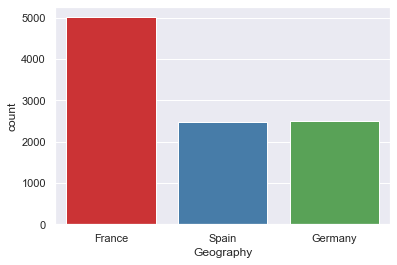

In [96]:
# Negara asal nasabah
sns.countplot(x='Geography', data=df);

Nasabah paling banyak berasal dari France

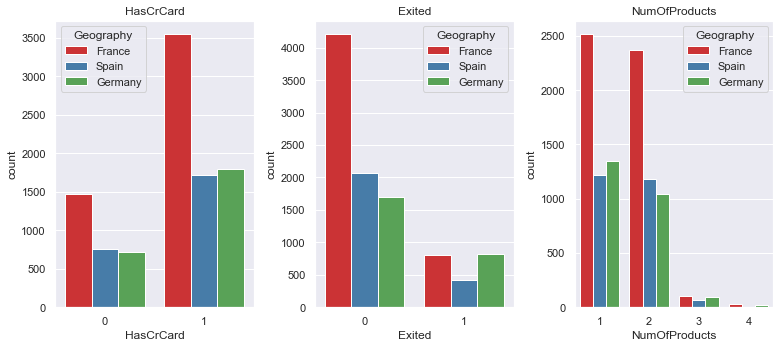

In [97]:
# Jumlah nasabah untuk tiap categorical variables, dibagi berdasarkan asal negaranya
features = ['HasCrCard', 'Exited', 'NumOfProducts']
plt.figure(figsize=(11, 5))
sns.set(palette='Set1')
plotnumber = 1

for feature in features:
    ax = plt.subplot(1, 3, plotnumber)
    sns.countplot(x=feature, hue='Geography', data=df)
    plt.xlabel(feature)
    plt.title(feature)
    plotnumber += 1
    plt.tight_layout();

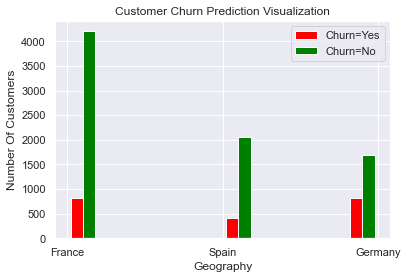

In [98]:
# Perbandingan churn customers pada tiap negara
geo_churn_no = df[df.Exited==0]['Geography']
geo_churn_yes = df[df.Exited==1]['Geography']

plt.xlabel('Geography')
plt.ylabel('Number Of Customers')
plt.title('Customer Churn Prediction Visualization')
plt.hist([geo_churn_yes, geo_churn_no], color=['red', 'green'], label=['Churn=Yes', 'Churn=No'])
plt.legend();

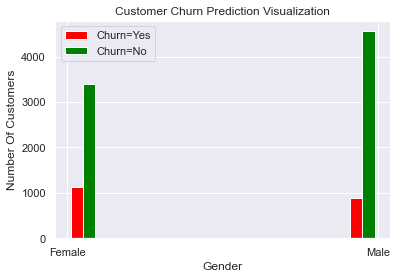

In [99]:
# Perbandingan churn customers pada tiap gender

gender_churn_no = df[df.Exited==0]['Gender']
gender_churn_yes = df[df.Exited==1]['Gender']

plt.xlabel('Gender')
plt.ylabel('Number Of Customers')
plt.title('Customer Churn Prediction Visualization')
plt.hist([gender_churn_yes, gender_churn_no], color=['red', 'green'], label=['Churn=Yes', 'Churn=No'])
plt.legend();

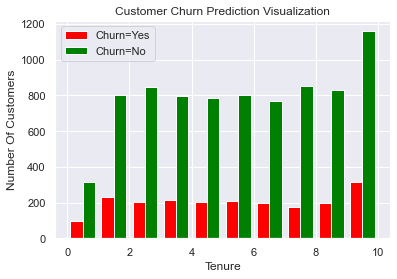

In [100]:
# Perbandingan churn customers untuk tiap lama tahun Tenure/masa cicilan

tenure_churn_no = df[df.Exited==0].Tenure
tenure_churn_yes = df[df.Exited==1].Tenure

plt.xlabel('Tenure')
plt.ylabel('Number Of Customers')
plt.title('Customer Churn Prediction Visualization')
plt.hist([tenure_churn_yes, tenure_churn_no], color=['red', 'green'], label=['Churn=Yes', 'Churn=No'])
plt.legend();

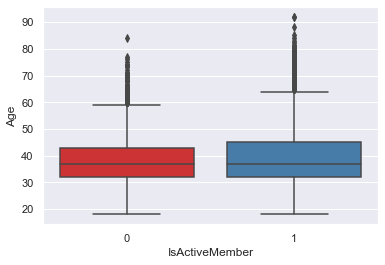

In [101]:
# sebaran umur pada active member dan non-active member
sns.boxplot(x='IsActiveMember', y='Age', data=df);

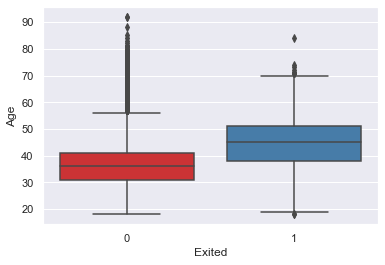

In [102]:
# sebaran umur pada churn customer dan non-churn customer
sns.boxplot(x='Exited', y='Age', data=df);

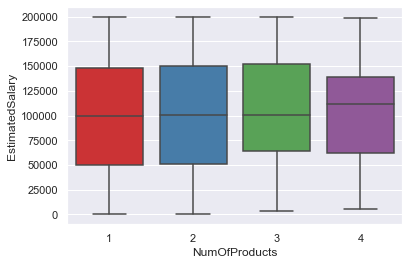

In [103]:
# sebaran gaji pada tiap jumlah product yang digunakan oleh nasabah

sns.boxplot(x='NumOfProducts', y='EstimatedSalary', data=df);

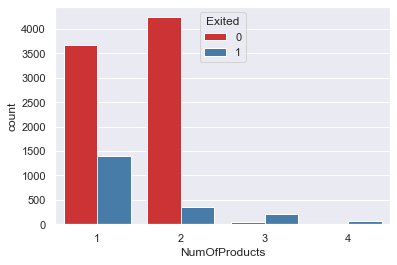

In [150]:
sns.countplot(x='NumOfProducts', hue='Exited', data=df);

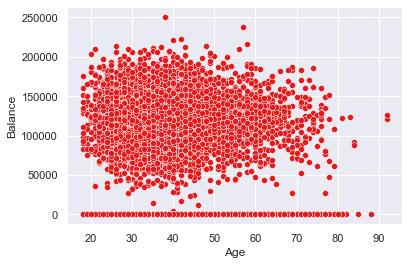

In [104]:
# korelasi antara umur dan saldo
sns.scatterplot(x='Age', y='Balance', data=df);

## **Drop unnecessary features**

In [105]:
# Drop some columns
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)
df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


## **Data splitting**

In [106]:
X = df.drop(['Exited'], axis=1)
y = df['Exited']

In [107]:
# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    stratify=y,
    test_size=0.2,
    random_state=0
)

## **Data preprocessing**

In [108]:
# Transformer scheme
transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(drop='first'), ['Geography', 'Gender'])
], remainder='passthrough')

In [109]:
# resampling
smote = SMOTE(random_state=0)
rus = RandomUnderSampler(random_state=0)
ros = RandomOverSampler(random_state=0)


## **Model benchmark**

In [110]:
# DecsionTree
tree = DecisionTreeClassifier(random_state=0)

# RandomForest
rf = RandomForestClassifier(random_state=0)

# Adaboost
ada = AdaBoostClassifier(tree, random_state=0)

# Gradientboost
gbc = GradientBoostingClassifier(random_state=0)

# ExtremeGradientBoost
xgbc = XGBClassifier(random_state=0, verbosity=0)

In [111]:
# Define imbalanced treatment method
models = [tree, rf, ada, gbc, xgbc]
score = []
nilai_mean = []
nilai_std = []

# F2 score (Karena cost dari FN (diprediksi tidak churn, padahal aslinya churn) lebih tinggi dari pada FP (diprediksi churn, padahal aslinya tidak churn))
f2_score = make_scorer(fbeta_score, beta=2)

for i in models:

    skfold = StratifiedKFold(n_splits=5)
    estimator = Pipeline([
        ('transformer', transformer),
        ('scaler', RobustScaler()),
        ('balancing', smote),
        ('model', i)
    ])

    model_cv = cross_val_score(
        estimator, 
        X_train, 
        y_train, 
        cv=skfold, 
        scoring=f2_score, 
        error_score='raise'
        )

    print(model_cv, i)

    score.append(model_cv)
    nilai_mean.append(model_cv.mean())
    nilai_std.append(model_cv.std())

[0.56503826 0.55754323 0.56169965 0.56488992 0.51153164] DecisionTreeClassifier(random_state=0)
[0.60012438 0.60274828 0.62770563 0.60513447 0.54790232] RandomForestClassifier(random_state=0)
[0.56924883 0.57498518 0.55131965 0.55878929 0.50942285] AdaBoostClassifier(base_estimator=DecisionTreeClassifier(random_state=0),
                   random_state=0)
[0.65033273 0.64564565 0.66185319 0.64217443 0.63946407] GradientBoostingClassifier(random_state=0)
[0.54278416 0.57482338 0.55732484 0.56746532 0.56579784] XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, gamma=None,
              gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
        

In [112]:
pd.DataFrame({
    'model':['tree', 'rf',' ada', 'gbc', 'xgbc'],
    'mean':nilai_mean,
    'std':nilai_std
})

,model,mean,std
0,tree,0.552141,0.020487
1,rf,0.596723,0.026314
2,ada,0.552753,0.023162
3,gbc,0.647894,0.007869
4,xgbc,0.561639,0.010947


Model GradientBoost dan XGBoost dipilih menjadi 2 model paling optimal karena memiliki nilai recall rata-rata paling tinggi.



## **Hyperparameter Tuning**

### Gradient Boost

In [113]:
list(np.arange(2,10)/10)

[0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

In [114]:
# kedalaman pohon
max_depth = list(np.arange(1,10))

# learning rate
learning_rate = list(np.arange(1,100)/100)

# jumlah pohon
n_estimators = list(np.arange(50,500))

# jumlah baris train set tiap pohon (% dari total baris train set)
subsample = list(np.arange(2,10)/10)

# jumlah feature yang digunakan untuk pertimbangan splitting (% dari total kolom train set)
max_features = list(np.arange(1,10))

# Hyperparameter space GBC
hyperparam_space_gbc = {
    'balancing':[smote, rus, ros, None],
    'model__max_depth':max_depth , 
    'model__learning_rate':learning_rate,
    'model__n_estimators':n_estimators,
    'model__subsample':subsample,
    'model__max_features':max_features
}

In [115]:
# Stratified cross validation
skf = StratifiedKFold(n_splits = 5)

# Benchmark model 1
gbc = GradientBoostingClassifier(random_state=0)

# Create the algorithm chains
estimator_gbc = Pipeline([
    ('tansformer', transformer),
    ('scaler', RobustScaler()),
    ('balancing', smote), 
    ('model', gbc)
    ])

# Hyperparameter tuning
random_gbc = RandomizedSearchCV(
    estimator_gbc, 
    param_distributions = hyperparam_space_gbc, 
    cv = skf, 
    scoring = f2_score, 
    n_jobs = -1, 
    random_state=0,
    n_iter=30
)

In [116]:
random_gbc.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
                   estimator=Pipeline(steps=[('tansformer',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('onehot',
                                                                               OneHotEncoder(drop='first'),
                                                                               ['Geography',
                                                                                'Gender'])])),
                                             ('scaler', RobustScaler()),
                                             ('balancing',
                                              SMOTE(random_state=0)),
                                             ('model',
                                              GradientBoostingClassifier(random_st...
                                                                 0.23, 0.24,
                                                                 0.25, 0.26,
                                                                 0.27, 0.28,
                                                                 0.29, 0.3, ...],
                                        'model__max_depth': [1, 2, 3, 4, 5, 6,
                                                             7, 8, 9],
                                        'model__max_features': [1, 2, 3, 4, 5,
                                                                6, 7, 8, 9],
                                        'model__n_estimators': [50, 51, 52, 53,
                                                                54, 55, 56, 57,
                                                                58, 59, 60, 61,
                                                                62, 63, 64, 65,
                                                                66, 67, 68, 69,
                                                                70, 71, 72, 73,
                                                                74, 75, 76, 77,
                                                                78, 79, ...],
                                        'model__subsample': [0.2, 0.3, 0.4, 0.5,
                                                             0.6, 0.7, 0.8,
                                                             0.9]},
                   random_state=0, scoring=make_scorer(fbeta_score, beta=2))

In [117]:
pd.DataFrame(random_gbc.cv_results_).sort_values(by='rank_test_score').head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__subsample,param_model__n_estimators,param_model__max_features,param_model__max_depth,param_model__learning_rate,param_balancing,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
23,6.127945,0.141479,0.068216,0.003468,0.7,461,5,7,0.27,RandomUnderSampler(random_state=0),"{'model__subsample': 0.7, 'model__n_estimators...",0.668790,0.672338,0.662879,0.655340,0.683163,0.668502,0.009323,1
15,0.443348,0.038099,0.023685,0.005052,0.4,107,1,4,0.26,RandomUnderSampler(random_state=0),"{'model__subsample': 0.4, 'model__n_estimators...",0.655471,0.676998,0.686543,0.651226,0.671883,0.668424,0.013246,2
4,2.125869,0.299299,0.026902,0.007344,0.5,56,3,8,0.03,RandomOverSampler(random_state=0),"{'model__subsample': 0.5, 'model__n_estimators...",0.706085,0.674391,0.669591,0.652931,0.633431,0.667286,0.024139,3
3,0.729971,0.114464,0.015679,0.005285,0.5,65,8,1,0.12,RandomOverSampler(random_state=0),"{'model__subsample': 0.5, 'model__n_estimators...",0.681313,0.674536,0.687743,0.633880,0.647059,0.664906,0.020807,4
11,3.818852,0.338618,0.025603,0.003201,0.8,486,4,1,0.5,RandomOverSampler(random_state=0),"{'model__subsample': 0.8, 'model__n_estimators...",0.680066,0.658192,0.655192,0.656650,0.651319,0.660284,0.010151,5


In [118]:
print('GBC')
print('Best_score:', random_gbc.best_score_)
print('Best_params:', random_gbc.best_params_)


GBC
Best_score: 0.6685018966975007
Best_params: {'model__subsample': 0.7, 'model__n_estimators': 461, 'model__max_features': 5, 'model__max_depth': 7, 'model__learning_rate': 0.27, 'balancing': RandomUnderSampler(random_state=0)}


### XGBoost

In [119]:
# kedalaman pohon
max_depth = list(np.arange(1,11))

# learning rate
learning_rate = list(np.arange(0.01, 1.0, 0.01))

# jumlah pohon
n_estimators = list(np.arange(100,201))

# jumlah baris tiap pohon (% dari total baris train set)
subsample = list(np.arange(0.2, 1.0, 0.1))

# gamma (min_impurity_decrease)
gamma = list(np.arange(1,11))

# jumlah feature yang digunakan untuk tiap pohon (% dari total kolom train set)
colsample_bytree = list(np.arange(0.1, 1.0, 0.2))

# alpha (regularization)
reg_alpha = list(np.logspace(-3,3,7))


# Hyperparam space XGboost
hyperparam_space_xgbc = {
    'balancing':[smote, rus, ros, None],
    'model__max_depth':max_depth, 
    'model__learning_rate':learning_rate,
    'model__n_estimators':n_estimators,
    'model__subsample':subsample,
    'model__gamma':gamma,
    'model__colsample_bytree':colsample_bytree,
    'model__reg_alpha': reg_alpha
}

In [120]:
# Benchmark model 2
xgbc = XGBClassifier(random_state=0, verbosity=0)

# Create the algorithm chains
estimator_xgbc = Pipeline([
        ('tansformer', transformer),
        ('balancing', smote), 
        ('model', xgbc)
        ])

# Hyperparameter tuning
random_xgbc = RandomizedSearchCV(
    estimator_xgbc, 
    param_distributions = hyperparam_space_xgbc, 
    cv = skf, 
    scoring = f2_score, 
    n_jobs = -1,  
    random_state=0,
    n_iter=30 
)

In [121]:
random_xgbc.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
                   estimator=Pipeline(steps=[('tansformer',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('onehot',
                                                                               OneHotEncoder(drop='first'),
                                                                               ['Geography',
                                                                                'Gender'])])),
                                             ('balancing',
                                              SMOTE(random_state=0)),
                                             ('model',
                                              XGBClassifier(base_score=None,
                                                            booster=None,
                                                            callbacks=None,
                                                            cols...
                                                                112, 113, 114,
                                                                115, 116, 117,
                                                                118, 119, 120,
                                                                121, 122, 123,
                                                                124, 125, 126,
                                                                127, 128, 129, ...],
                                        'model__reg_alpha': [0.001, 0.01, 0.1,
                                                             1.0, 10.0, 100.0,
                                                             1000.0],
                                        'model__subsample': [0.2,
                                                             0.30000000000000004,
                                                             0.4000000000000001,
                                                             0.5000000000000001,
                                                             0.6000000000000001,
                                                             0.7000000000000002,
                                                             0.8000000000000003,
                                                             0.9000000000000001]},
                   random_state=0, scoring=make_scorer(fbeta_score, beta=2))

In [122]:
pd.DataFrame(random_xgbc.cv_results_).sort_values(by='rank_test_score').head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__subsample,param_model__reg_alpha,param_model__n_estimators,param_model__max_depth,param_model__learning_rate,param_model__gamma,...,param_balancing,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
1,1.466079,0.094308,0.021104,0.003875,0.9,0.01,194,3,0.22,2,...,RandomUnderSampler(random_state=0),"{'model__subsample': 0.9000000000000001, 'mode...",0.691635,0.675978,0.664105,0.662252,0.654102,0.669614,0.013043,1
19,0.486314,0.036151,0.017905,0.003104,0.2,10.0,109,2,0.33,8,...,RandomOverSampler(random_state=0),"{'model__subsample': 0.2, 'model__reg_alpha': ...",0.679956,0.664804,0.680571,0.654436,0.657609,0.667475,0.010971,2
9,0.219377,0.024320,0.016444,0.000884,0.2,0.1,165,1,0.2,3,...,RandomUnderSampler(random_state=0),"{'model__subsample': 0.2, 'model__reg_alpha': ...",0.676342,0.665188,0.686707,0.644637,0.655471,0.665669,0.014853,3
10,0.228188,0.021924,0.018138,0.002944,0.7,1.0,128,3,0.49,5,...,RandomUnderSampler(random_state=0),"{'model__subsample': 0.7000000000000002, 'mode...",0.685484,0.672757,0.664084,0.651581,0.646052,0.663992,0.014245,4
3,0.921150,0.399576,0.022627,0.004831,0.5,1.0,189,5,0.82,9,...,RandomUnderSampler(random_state=0),"{'model__subsample': 0.5000000000000001, 'mode...",0.689468,0.657459,0.658830,0.650384,0.663152,0.663859,0.013447,5


In [123]:
print('XGBoost')
print('Best_score:', random_xgbc.best_score_)
print('Best_params:', random_xgbc.best_params_)

XGBoost
Best_score: 0.6696142913261218
Best_params: {'model__subsample': 0.9000000000000001, 'model__reg_alpha': 0.01, 'model__n_estimators': 194, 'model__max_depth': 3, 'model__learning_rate': 0.22, 'model__gamma': 2, 'model__colsample_bytree': 0.5000000000000001, 'balancing': RandomUnderSampler(random_state=0)}


f2 score di train set:
- benchmark model gradient boost: 0.647
- hyperparameter tuning gradient boost: 0.668
- hyperparameter tuning XGBoost: 0.669


## **Performance in Test Set**

### Before Hyperparameter Tuning

In [124]:
models={
    'GradientBoosting': GradientBoostingClassifier(random_state=0),
    'XGBoost': XGBClassifier(random_state=0, verbosity=0) 
}

score=[]

for i in models:

    model = Pipeline([
        ('transformer', transformer),
        ('balancing', smote),
        ('model', models[i])
    ])

    # fitting
    model.fit(X_train, y_train)

    # predict
    y_pred = model.predict(X_test)

    # recall score
    score.append([fbeta_score(y_test, y_pred, beta=2)])

score_before_tuning = pd.DataFrame(score, columns=['F2 score'], index = models.keys())
score_before_tuning


,F2 score
GradientBoosting,0.531527
XGBoost,0.509886


### After Hyperparameter Tuning

In [125]:
# best model
gbc_tuning = random_gbc.best_estimator_

# fitting
gbc_tuning.fit(X_train, y_train)

# predict
y_pred_gbc_tuning = gbc_tuning.predict(X_test)

# recall score
f2score_gbc_tuning = fbeta_score(y_test, y_pred_gbc_tuning, beta=2)
f2score_gbc_tuning

0.6408020924149957

In [126]:
# best model
xgbc_tuning = random_xgbc.best_estimator_

# fitting
xgbc_tuning.fit(X_train, y_train)

# predict
y_pred_xgbc_tuning = xgbc_tuning.predict(X_test)

# recall score
f2score_xgbc_tuning = fbeta_score(y_test, y_pred_xgbc_tuning, beta=2)
f2score_xgbc_tuning

0.666965085049239

In [127]:
score_list = [f2score_gbc_tuning, f2score_xgbc_tuning]

models = ['GradientBoosting', 'XGBoost']

score_after_tuning = pd.DataFrame({
    'Model': models,
    'F2 score': score_list
})

score_after_tuning

,Model,F2 score
0,GradientBoosting,0.640802
1,XGBoost,0.666965


## **Comparison (Test Set)**

In [128]:
score_before_tuning

,F2 score
GradientBoosting,0.531527
XGBoost,0.509886


In [129]:
score_after_tuning

,Model,F2 score
0,GradientBoosting,0.640802
1,XGBoost,0.666965


In [130]:
print('GradientBoostingClassifier')
print(classification_report(y_test, y_pred_gbc_tuning))

GradientBoostingClassifier
              precision    recall  f1-score   support

           0       0.92      0.77      0.83      1593
           1       0.44      0.72      0.55       407

    accuracy                           0.76      2000
   macro avg       0.68      0.74      0.69      2000
weighted avg       0.82      0.76      0.78      2000



In [131]:
print('XGBoost')
print(classification_report(y_test, y_pred_xgbc_tuning))

XGBoost
              precision    recall  f1-score   support

           0       0.92      0.81      0.86      1593
           1       0.49      0.73      0.59       407

    accuracy                           0.79      2000
   macro avg       0.71      0.77      0.72      2000
weighted avg       0.83      0.79      0.81      2000



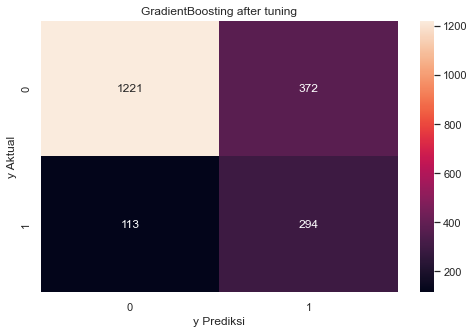

In [132]:
# GradientBoost after tuning
f, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_gbc_tuning), annot=True, fmt='.0f', ax=ax)
plt.xlabel('y Prediksi')
plt.ylabel('y Aktual')
plt.title('GradientBoosting after tuning');

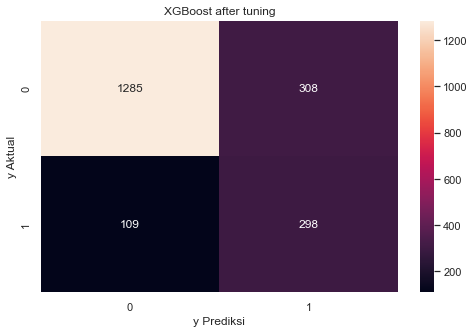

In [133]:
# Model XGBoost after tuning

f, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_xgbc_tuning), annot=True, fmt='.0f', ax=ax)
plt.xlabel('y Prediksi')
plt.ylabel('y Aktual')
plt.title('XGBoost after tuning');

In [134]:
print(score_before_tuning.iloc[0])
print(score_after_tuning.iloc[0])


F2 score    0.531527
Name: GradientBoosting, dtype: float64
Model       GradientBoosting
F2 score            0.640802
Name: 0, dtype: object


## **Summary**
---
Gradient Boost

   - Train Set:
      - Before tuning: 0.56
      - After tuning: 0.66

   - Test Set:
      - Before tuning: 0.53
      - After tuning: 0.66

---
XGBoost

   - Train Set:
      - Before tuning: 0.54
      - After tuning: 0.67

   - Test Set:
      - Before tuning: 0.52
      - After tuning: 0.67

---

Hyperparameter tuning berhasil meningkatkan F2 Score pda test set dari model dengan XGBoost sebesar 0.15. 
Performa model sebesar 0.67 bisa dikatakan belum bagus karena jumlah False Negative masih sekitar 1/4 dari total kelas 1 (churn). 

Metric F2 Score digunakan karena cost function dari False Negative dianggap lebih besar dari False Positif, sehingga jumlah False Negative yang dihasilkan oleh model harus diminimalkan. 
Namun, karena jumlah kelas 1 hanya sekitar 20% dari jumlah data, menggunakan teknik resampling saja belum cukup untuk bisa menghasilkan model dengan performa optimal, 
harus dicoba dengan melakukan pendekatan lain, misalnya dikombinasikan dengan feature engineering.


## Feature Importance

In [149]:
xgbc_tuning

Pipeline(steps=[('tansformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot',
                                                  OneHotEncoder(drop='first'),
                                                  ['Geography', 'Gender'])])),
                ('balancing', RandomUnderSampler(random_state=0)),
                ('model',
                 XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
                               colsample_bylevel=1, colsample_bynode=1,
                               colsample_bytree=0.5000000000000001,
                               early...
                               gamma=2, gpu_id=-1, grow_policy='depthwise',
                               importance_type=None, interaction_constraints='',
                               learning_rate=0.22, max_bin=256,
                               max_cat_to_onehot=4, max_delta_step=0,
                               max_depth=3, max_leaves=0, min_child_weight=1,
                               missing=nan, monotone_constraints='()',
                               n_estimators=194, n_jobs=0, num_parallel_tree=1,
                               predictor='auto', random_state=0, reg_alpha=0.01,
                               reg_lambda=1, ...))])

In [135]:
xgbc_tuning['model'].feature_importances_

array([0.08947399, 0.04207718, 0.0871093 , 0.03378472, 0.19434133,
       0.03364481, 0.05517851, 0.25517386, 0.03285741, 0.14296776,
       0.03339105], dtype=float32)

In [136]:
feat_cat = list(transformer.transformers_[0][1].get_feature_names_out())
feat_num =list(X_train.columns[transformer.transformers_[1][2]])

feat = feat_cat + feat_num

In [137]:
imp = pd.DataFrame({
    'feature':feat,
    'importance':xgbc_tuning['model'].feature_importances_
}).sort_values('importance', ascending=False)

imp

,feature,importance
7,NumOfProducts,0.255174
4,Age,0.194341
9,IsActiveMember,0.142968
0,Geography_Germany,0.089474
2,Gender_Male,0.087109
6,Balance,0.055179
1,Geography_Spain,0.042077
3,CreditScore,0.033785
5,Tenure,0.033645
10,EstimatedSalary,0.033391


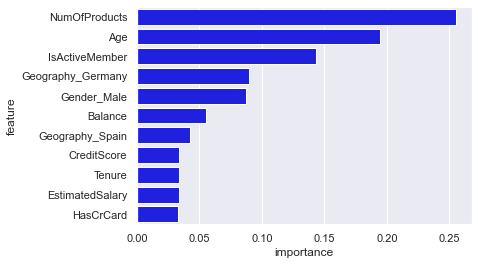

In [138]:
sns.barplot(data=imp, y='feature', x='importance', color='b');

In [139]:
ct = pd.crosstab(df['HasCrCard'], df['Exited'])
ct

Exited,0,1
HasCrCard,,
0,2332,613
1,5631,1424


<AxesSubplot:xlabel='HasCrCard', ylabel='count'>

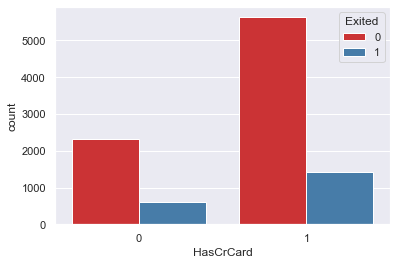

In [140]:
sns.countplot(data=df, x='HasCrCard', hue='Exited')

<AxesSubplot:xlabel='NumOfProducts', ylabel='count'>

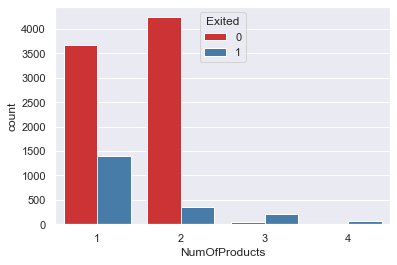

In [141]:
sns.countplot(data=df, x='NumOfProducts', hue='Exited')

## Save Model

**pickle**

In [142]:
# Save Model
import pickle

# best model
xgbc_tuning = random_xgbc.best_estimator_

xgbc_tuning.fit(X, y)

pickle.dump(xgbc_tuning, open('Model_XGBC.sav', 'wb'))

In [143]:
# Load model

filename = 'Model_XGBC.sav'
loaded_model = pickle.load(open(filename, 'rb'))

In [144]:
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [145]:
new_cust = pd.DataFrame({
    'CreditScore':[600],
    'Geography':['Spain'],
    'Gender':['Male'],
    'Age':[50],
    'Tenure':[5],
    'Balance':[100000],
    'NumOfProducts':[1],
    'HasCrCard':[1],
    'IsActiveMember':[0],
    'EstimatedSalary':[100000]
})

new_cust

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,600,Spain,Male,50,5,100000,1,1,0,100000


In [146]:
loaded_model.predict(new_cust)

array([1])

**joblib**

In [147]:
import joblib

# best model
xgbc_tuning = random_xgbc.best_estimator_

xgbc_tuning.fit(X, y)

# saving model
joblib.dump(xgbc_tuning, "model_XGBC_joblib")

# loading model
model_joblib = joblib.load("model_XGBC_joblib")

In [148]:
model_joblib.predict(new_cust)

array([1])